# 1. Explore the completed baseline

Read the [Experiment 03 guide](../README.md) for the full explanation. A patch copies one internal vector from a donor input into a receiver input. We inspect saved answers here. We do not load Qwen or change any result.

Run all cells in order. This notebook needs only pandas, matplotlib and Pillow. It runs on CPU. Images are optional; all numbers work without them. In Colab, clone the feature branch, open this notebook and run it. No Drive login is needed. If packages are missing, install `pandas matplotlib Pillow` in your notebook environment first.
For Colab, run these lines in a setup cell before running this notebook (skip cloning if the checkout already exists):

```python
!git clone --branch feature/complete-research-pipeline https://github.com/SathyaHamsiniP/looking-beyond-attention.git /content/looking-beyond-attention
%cd /content/looking-beyond-attention
%pip install pandas matplotlib Pillow
```


In [1]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Jupyter starts beside the notebook. Colab may start at the checkout root.
here = Path.cwd().resolve()
candidates = [here, *here.parents]
ROOT = next((p for p in candidates if (p / 'raw/patches.csv').is_file()), None)
if ROOT is None:
    ROOT = next((p / 'three-operand-experiments/experiments/03-activation-patching/baseline-analysis'
                 for p in candidates if (p / 'three-operand-experiments/experiments/03-activation-patching/baseline-analysis/raw/patches.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned repository, or change the working folder to the checkout root.')
rows = pd.read_csv(ROOT / 'raw/patches.csv')
manifest = json.loads((ROOT / 'derived/input_manifest.json').read_text())
metrics = pd.read_json(ROOT / 'derived/metrics.json')
assert len(rows) == 3456
print('Loaded 3,456 saved trials. No model is running.')

Loaded 3,456 saved trials. No model is running.


# 2. Choose one patch

Edit the four values below, then run the cells in this section again. A rotation is one answer-label order. A layer is one processing block. `final` means the last input token; `previous` means the token just before it. A token is one position in the prepared input.

The printed lists show valid choices. The default is a real trial where the donor gives a wrong answer.

In [2]:
print('Pairs:', *rows.pair_id.unique(), sep='\n')
print('Rotations:', sorted(rows.rotation.unique()))
print('Layers: 1 through 32; positions: final, previous')

pair = 'test_R1_00__different__test_R2_00'
rotation = 0
layer = 32
token_position = 'final'

selected = rows[(rows.pair_id == pair) & (rows.rotation == rotation) &
                (rows.layer == layer) & (rows.position == token_position)]
if len(selected) != 1:
    raise ValueError('Choose one valid pair, rotation, layer and token position from the lists above.')
trial = selected.iloc[0]
print('Receiver true rule:', trial.receiver_rule, '| original answer:', trial.receiver_prediction)
print('Donor true rule:', trial.donor_rule, '| original answer:', trial.donor_prediction)
print('Receiver answer after patch:', trial.patched_prediction)

Pairs:
test_R1_00__same__test_R1_01
test_R1_00__different__test_R2_00
test_R1_00__different__test_R3_00
test_R1_01__same__test_R1_02
test_R1_01__different__test_R2_01
test_R1_01__different__test_R3_01
test_R2_00__same__test_R2_01
test_R2_00__different__test_R1_00
test_R2_00__different__test_R3_00
test_R2_01__same__test_R2_02
test_R2_01__different__test_R1_01
test_R2_01__different__test_R3_01
test_R3_00__same__test_R3_01
test_R3_00__different__test_R1_00
test_R3_00__different__test_R2_00
test_R3_01__same__test_R3_02
test_R3_01__different__test_R1_01
test_R3_01__different__test_R2_01
Rotations: [np.int64(0), np.int64(1), np.int64(2)]
Layers: 1 through 32; positions: final, previous
Receiver true rule: R1 | original answer: R2
Donor true rule: R2 | original answer: R3
Receiver answer after patch: R3


In [3]:
# Look for the separate dataset beside the experiment folders. Missing images are fine.
dataset = ROOT.parents[2] / 'data-1000'
release = 'https://github.com/SathyaHamsiniP/looking-beyond-attention/releases/tag/dataset-v1'
for role in ('receiver', 'donor'):
    item = manifest[f"{trial[role + '_set']}:{rotation}"]
    print('\n' + role.upper() + ': ' + trial[role + '_set'])
    display(pd.DataFrame({'order': range(1, 11), 'filename': item['images'],
                          'A/B/C (inspection only)': [''.join(map(str,b)) for b in item['bits']]}))
    print('Answer mapping:', item['mapping'])
    print('Full prompt:\n' + item['prompt'])
    paths = [dataset / 'images' / name for name in item['images']]
    if all(p.is_file() for p in paths):
        fig, axes = plt.subplots(2, 5, figsize=(15, 6))
        for i, (ax, path) in enumerate(zip(axes.flat, paths)):
            with Image.open(path) as image:
                ax.imshow(image.convert('RGB'))
            ax.set_title(f"{i+1}: {''.join(map(str,item['bits'][i]))}")
            ax.axis('off')
        plt.tight_layout(); plt.show()
    else:
        print('Images are optional. Download dataset-v1 from', release)
        print('Put images/ and metadata.json in', dataset, 'or edit dataset above.')
print('The bit labels help us inspect the inputs. Qwen received images, not these labels.')


RECEIVER: test_R1_00


,order,filename,A/B/C (inspection only)
0,1,scene_001_109.png,001
1,2,scene_110_123.png,110
2,3,scene_011_100.png,011
3,4,scene_001_123.png,001
4,5,scene_101_106.png,101
5,6,scene_111_113.png,111
6,7,scene_011_114.png,011
7,8,scene_001_105.png,001
8,9,scene_001_104.png,001
9,10,scene_101_104.png,101


Answer mapping: {'X': 'R1', 'Y': 'R2', 'Z': 'R3'}
Full prompt:
Images 1-10 all satisfy ONE hidden Boolean rule.

A is true when a green cube is present.
B is true when a blue sphere is present.
C is true when a red cylinder is present.
Each concept requires the exact colour AND shape.
Any other object is an irrelevant distractor.

Candidate rules:
X: (A AND B) OR C
Y: (A AND C) OR B
Z: (B AND C) OR A

AND requires both inputs to be true.
OR requires at least one input to be true, including both.
Follow the parentheses.

Pick the rule consistent with every image.
Reply with nothing but its label: X, Y, or Z.
ANSWER:
Images are optional. Download dataset-v1 from https://github.com/SathyaHamsiniP/looking-beyond-attention/releases/tag/dataset-v1
Put images/ and metadata.json in /workspace/looking-beyond-attention/three-operand-experiments/data-1000 or edit dataset above.

DONOR: test_R2_00


,order,filename,A/B/C (inspection only)
0,1,scene_010_119.png,010
1,2,scene_111_103.png,111
2,3,scene_010_104.png,010
3,4,scene_110_101.png,110
4,5,scene_110_119.png,110
5,6,scene_111_110.png,111
6,7,scene_010_110.png,010
7,8,scene_010_100.png,010
8,9,scene_011_124.png,011
9,10,scene_101_120.png,101


Answer mapping: {'X': 'R1', 'Y': 'R2', 'Z': 'R3'}
Full prompt:
Images 1-10 all satisfy ONE hidden Boolean rule.

A is true when a green cube is present.
B is true when a blue sphere is present.
C is true when a red cylinder is present.
Each concept requires the exact colour AND shape.
Any other object is an irrelevant distractor.

Candidate rules:
X: (A AND B) OR C
Y: (A AND C) OR B
Z: (B AND C) OR A

AND requires both inputs to be true.
OR requires at least one input to be true, including both.
Follow the parentheses.

Pick the rule consistent with every image.
Reply with nothing but its label: X, Y, or Z.
ANSWER:
Images are optional. Download dataset-v1 from https://github.com/SathyaHamsiniP/looking-beyond-attention/releases/tag/dataset-v1
Put images/ and metadata.json in /workspace/looking-beyond-attention/three-operand-experiments/data-1000 or edit dataset above.
The bit labels help us inspect the inputs. Qwen received images, not these labels.


In [4]:
def available_probabilities(row):
    table = []
    for stage in ('receiver', 'donor', 'patched'):
        known = {row.donor_rule: float(row[f'{stage}_p_donor_rule'])}
        if stage != 'donor':
            known[row.receiver_rule] = float(row[f'{stage}_p_receiver_rule'])
        reconstructed = None
        if stage != 'donor' and row.receiver_rule != row.donor_rule:
            reconstructed = next(r for r in ('R1','R2','R3') if r not in known)
            remainder = 1 - sum(known.values())
            if not -1e-5 <= remainder <= 1 + 1e-5:
                raise ValueError('Saved probabilities are inconsistent.')
            known[reconstructed] = min(1., max(0., remainder))
        for rule in ('R1','R2','R3'):
            table.append({'stage': stage, 'rule': rule,
                          'probability': known.get(rule, float('nan')),
                          'source': 'reconstructed: 1 minus the other two' if rule == reconstructed
                                    else ('saved' if rule in known else 'unavailable')})
    return pd.DataFrame(table)

probability_table = available_probabilities(trial)
display(probability_table)
print('NaN means unavailable, not zero. Probabilities are normalized only over X/Y/Z.')
print(f"We copied the donor vector at layer {layer}, at the {token_position} input position.")
print(f"The receiver answer went from {trial.receiver_prediction} to {trial.patched_prediction}.")
print(f"The donor true-rule probability changed by {100*trial.delta_p_donor_rule:.2f} percentage points.")
print('Answer changed:', bool(trial.changed_answer), '| changed to donor true rule:', bool(trial.changed_to_donor_rule))
print('Copying a donor answer does not mean copying a correct answer.')

,stage,rule,probability,source
0,receiver,R1,0.164777,saved
1,receiver,R2,0.427398,saved
2,receiver,R3,0.407826,reconstructed: 1 minus the other two
3,donor,R1,NaN,unavailable
4,donor,R2,0.362793,saved
5,donor,R3,NaN,unavailable
6,patched,R1,0.171371,saved
7,patched,R2,0.362793,saved
8,patched,R3,0.465836,reconstructed: 1 minus the other two


NaN means unavailable, not zero. Probabilities are normalized only over X/Y/Z.
We copied the donor vector at layer 32, at the final input position.
The receiver answer went from R2 to R3.
The donor true-rule probability changed by -6.46 percentage points.
Answer changed: True | changed to donor true rule: False
Copying a donor answer does not mean copying a correct answer.


# 3. Look across the run

Each plotted point averages repeated trials on the same small set of inputs. They are not independent image sets. A same-rule donor follows the receiver's rule. A different-rule donor follows another rule.

The signed change keeps the direction of each probability change. Opposite changes can cancel. The absolute change measures the size without the direction. A donor true-rule transfer is a changed answer to its generating rule. Donor predicted-answer transfer is a changed answer to what the donor actually chose, which can be wrong.

answer_change_rate.png


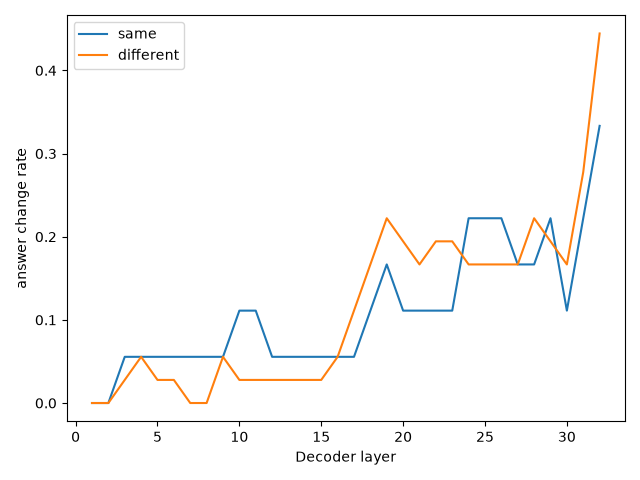

signed_change.png


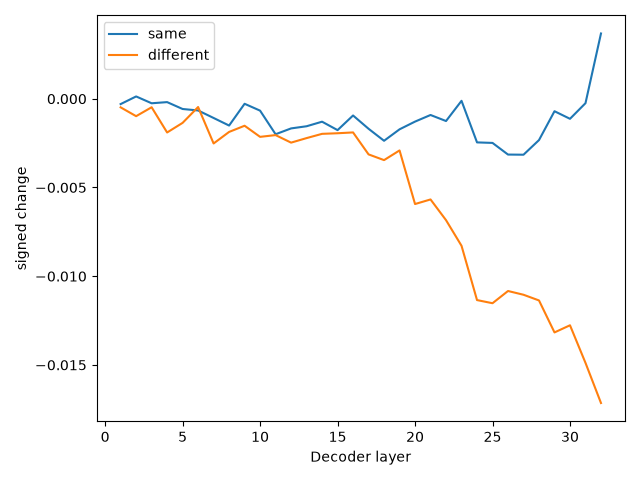

absolute_change.png


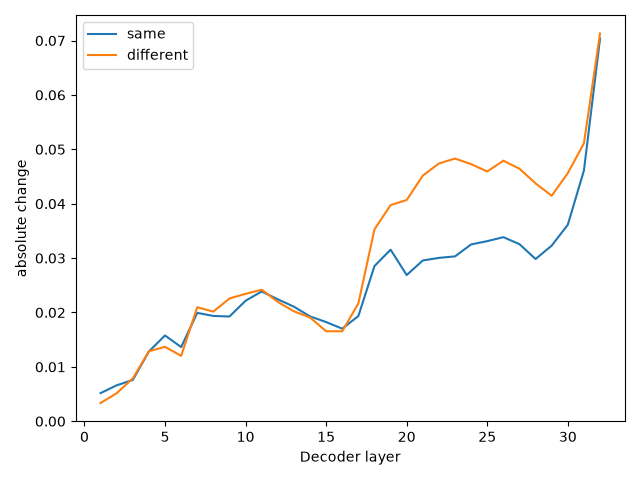

answer_bias.png


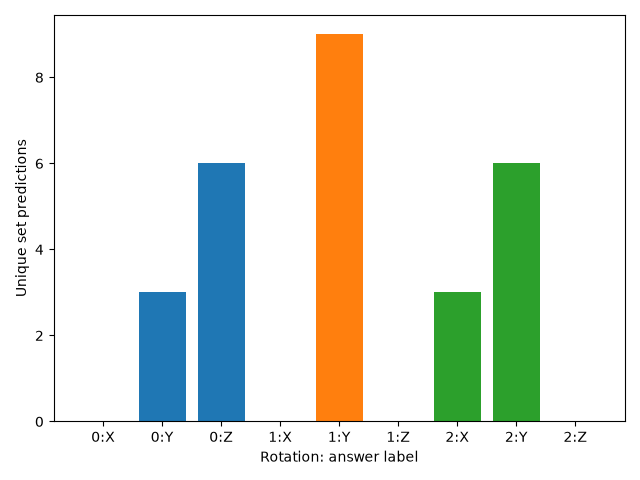

,condition,position,layer,n,answer_change_rate,donor_true_rule_change_rate,donor_prediction_change_rate,signed_change,absolute_change
31,different,final,32,36,0.444444,0.194444,0.444444,-0.017147,0.071304
95,same,final,32,18,0.333333,0.000000,0.333333,0.003679,0.070356


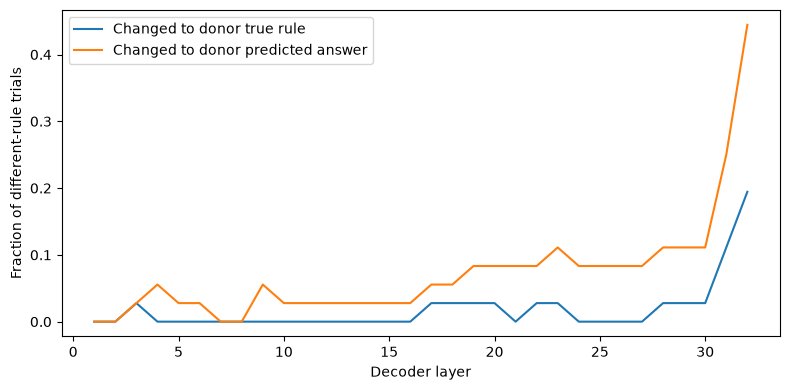

The two curves use all different-rule final-token trials as the denominator.
Option bias counts each original set once per rotation, including donor-only sets.


In [5]:
for filename in ('answer_change_rate.png', 'signed_change.png', 'absolute_change.png', 'answer_bias.png'):
    print(filename)
    with Image.open(ROOT / 'derived' / filename) as image:
        display(image.copy())

final_metrics = metrics[(metrics.position == 'final') & (metrics.layer == 32)]
display(final_metrics)
different = metrics[(metrics.condition == 'different') & (metrics.position == 'final')].sort_values('layer')
plt.figure(figsize=(8,4))
plt.plot(different.layer, different.donor_true_rule_change_rate, label='Changed to donor true rule')
plt.plot(different.layer, different.donor_prediction_change_rate, label='Changed to donor predicted answer')
plt.xlabel('Decoder layer'); plt.ylabel('Fraction of different-rule trials')
plt.legend(); plt.tight_layout(); plt.show()
print('The two curves use all different-rule final-token trials as the denominator.')
print('Option bias counts each original set once per rotation, including donor-only sets.')

# 4. What do the results tell us?

There are 18 pairs, three answer orders, 32 layers and two token positions: 3,456 trials. At layer 32, all 54 final-token patches reproduce the donor's predicted answer. Among 36 different-rule patches, 16 change the answer and seven change it to the donor's true rule.

The mean absolute donor-rule change at layer 32 is about 7.04 percentage points for same-rule patches and 7.13 for different-rule patches. Same-rule patches also change answers. Large changes alone therefore do not show rule transfer.

Layer 6 has the least negative signed average different-rule change. It is not a positive transfer result. No layer passes the chosen 0.05 control cutoff. That cutoff is an effect-size check, not a statistical significance test.

Later-layer patches affect answers, and the original predictions show answer-option and rule bias. At the final layer, copying the final vector puts the donor state directly before the answer readout. This does not identify where Boolean reasoning happens.

The original files and input manifest stay unchanged. We cannot recover missing same-rule probabilities, infer the original GPU run's code commit, or prove logical reasoning from these results. See the README for the full limits and the saved analysis for exact values.
## Reading the layer pattern without mistaking it for reasoning

There are three different things to look for: **signed change** (toward/away from donor's true rule), **absolute change** (size of shift, irrespective of direction), and **answer-change rate** (whether the winning option switches). A change of +2 and another of −4 percentage points have a signed mean of −1 pp but a mean absolute change of 3 pp.

**Layer 6 was not the biggest shift.** Its different-rule final-token signed mean was **−0.0466 pp**, the *least negative* average across the 32 layers, while its absolute mean was **1.20 pp**. Of 36 trials, **15 increased** the donor-rule probability, **20 decreased** it and **one was effectively unchanged**. All 32 different-rule final-token *averages* were negative, although individual trials could be positive.

Later layers generally changed answers more often. At layer 32, **16 of 36 different-rule** final-token trials changed the receiver's predicted answer, but only **7 of 36** changed it to the donor's *true* rule. The average absolute donor-rule shift there was **7.13 pp for different-rule** and **7.04 pp for same-rule** patches. A larger shift or an answer change therefore does **not** identify a Boolean-reasoning layer.

**For single-layer LoRA:** first decide what “shift” means, compare with same-rule controls, choose a candidate using validation data, and consider a control layer. There is no uniquely justified layer from this baseline alone. For the selected-layer table and explanations, see the [Experiment 03 guide](../README.md#reading-the-layer-wise-results-what-actually-shifts).
